<a href="https://colab.research.google.com/github/Erlanggaaghnaf/Algoritma-Kriptografi-Asimetris-RSA/blob/main/Tugas_EDA_ML.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
!pip install -q ucimlrepo

In [ ]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from ucimlrepo import fetch_ucirepo

# Mengambil dataset dari UCI
dataset = fetch_ucirepo(id=697)

# Menggabungkan fitur dan kolom target
X = dataset.data.features
y = dataset.data.targets
df = pd.concat([X, y], axis=1)

# Melihat ukuran dan contoh data
print("Ukuran dataset:", df.shape)
display(df.head())

# Memeriksa struktur dan tipe data
df.info()

# Memeriksa nilai kosong dan duplikat
print("\nNilai kosong:")
print(df.isnull().sum().sum())

print("\nJumlah baris duplikat:", df.duplicated().sum())

# Statistik deskriptif
display(df.describe().T)


Ukuran dataset: (4424, 37)


,Marital Status,Application mode,Application order,Course,Daytime/evening attendance,Previous qualification,Previous qualification (grade),Nacionality,Mother's qualification,Father's qualification,...,Curricular units 2nd sem (credited),Curricular units 2nd sem (enrolled),Curricular units 2nd sem (evaluations),Curricular units 2nd sem (approved),Curricular units 2nd sem (grade),Curricular units 2nd sem (without evaluations),Unemployment rate,Inflation rate,GDP,Target
0,1,17,5,171,1,1,122.0,1,19,12,...,0,0,0,0,0.000000,0,10.8,1.4,1.74,Dropout
1,1,15,1,9254,1,1,160.0,1,1,3,...,0,6,6,6,13.666667,0,13.9,-0.3,0.79,Graduate
2,1,1,5,9070,1,1,122.0,1,37,37,...,0,6,0,0,0.000000,0,10.8,1.4,1.74,Dropout
3,1,17,2,9773,1,1,122.0,1,38,37,...,0,6,10,5,12.400000,0,9.4,-0.8,-3.12,Graduate
4,2,39,1,8014,0,1,100.0,1,37,38,...,0,6,6,6,13.000000,0,13.9,-0.3,0.79,Graduate


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4424 entries, 0 to 4423
Data columns (total 37 columns):
 #   Column                                          Non-Null Count  Dtype  
---  ------                                          --------------  -----  
 0   Marital Status                                  4424 non-null   int64  
 1   Application mode                                4424 non-null   int64  
 2   Application order                               4424 non-null   int64  
 3   Course                                          4424 non-null   int64  
 4   Daytime/evening attendance                      4424 non-null   int64  
 5   Previous qualification                          4424 non-null   int64  
 6   Previous qualification (grade)                  4424 non-null   float64
 7   Nacionality                                     4424 non-null   int64  
 8   Mother's qualification                          4424 non-null   int64  
 9   Father's qualification                   

,count,mean,std,min,25%,50%,75%,max
Marital Status,4424.0,1.178571,0.605747,1.00,1.00,1.000000,1.000000,6.000000
Application mode,4424.0,18.669078,17.484682,1.00,1.00,17.000000,39.000000,57.000000
Application order,4424.0,1.727848,1.313793,0.00,1.00,1.000000,2.000000,9.000000
Course,4424.0,8856.642631,2063.566416,33.00,9085.00,9238.000000,9556.000000,9991.000000
Daytime/evening attendance,4424.0,0.890823,0.311897,0.00,1.00,1.000000,1.000000,1.000000
Previous qualification,4424.0,4.577758,10.216592,1.00,1.00,1.000000,1.000000,43.000000
Previous qualification (grade),4424.0,132.613314,13.188332,95.00,125.00,133.100000,140.000000,190.000000
Nacionality,4424.0,1.873192,6.914514,1.00,1.00,1.000000,1.000000,109.000000
Mother's qualification,4424.0,19.561935,15.603186,1.00,2.00,19.000000,37.000000,44.000000
Father's qualification,4424.0,22.275316,15.343108,1.00,3.00,19.000000,37.000000,44.000000


,Jumlah,Persentase (%)
Target,,
Graduate,2209,49.93
Dropout,1421,32.12
Enrolled,794,17.95


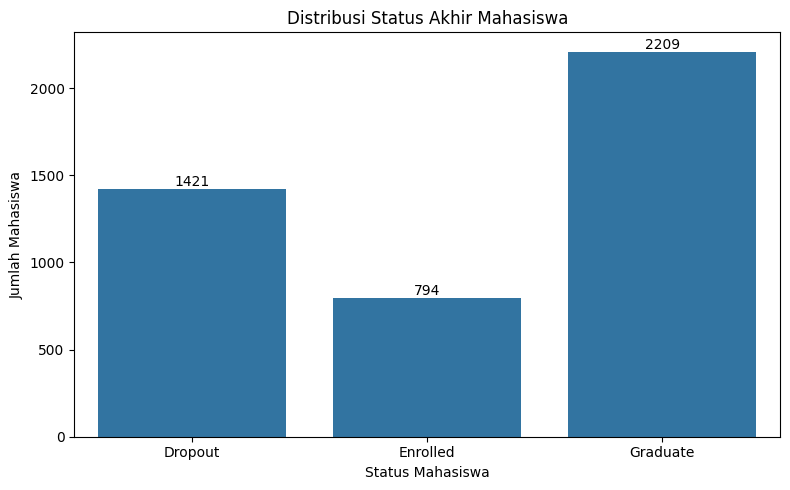

In [ ]:

# Menghitung jumlah dan persentase setiap status mahasiswa
target = "Target"

jumlah_status = df[target].value_counts()
persentase_status = (
    df[target].value_counts(normalize=True) * 100
)

ringkasan_status = pd.DataFrame({
    "Jumlah": jumlah_status,
    "Persentase (%)": persentase_status.round(2)
})

display(ringkasan_status)

# Membuat grafik distribusi status mahasiswa
plt.figure(figsize=(8, 5))

ax = sns.countplot(
    data=df,
    x=target,
    order=["Dropout", "Enrolled", "Graduate"]
)

plt.title("Distribusi Status Akhir Mahasiswa")
plt.xlabel("Status Mahasiswa")
plt.ylabel("Jumlah Mahasiswa")

# Menampilkan jumlah pada setiap batang
for bar in ax.patches:
    tinggi = bar.get_height()
    ax.annotate(
        f"{int(tinggi)}",
        (bar.get_x() + bar.get_width() / 2, tinggi),
        ha="center",
        va="bottom"
    )

plt.tight_layout()
plt.show()


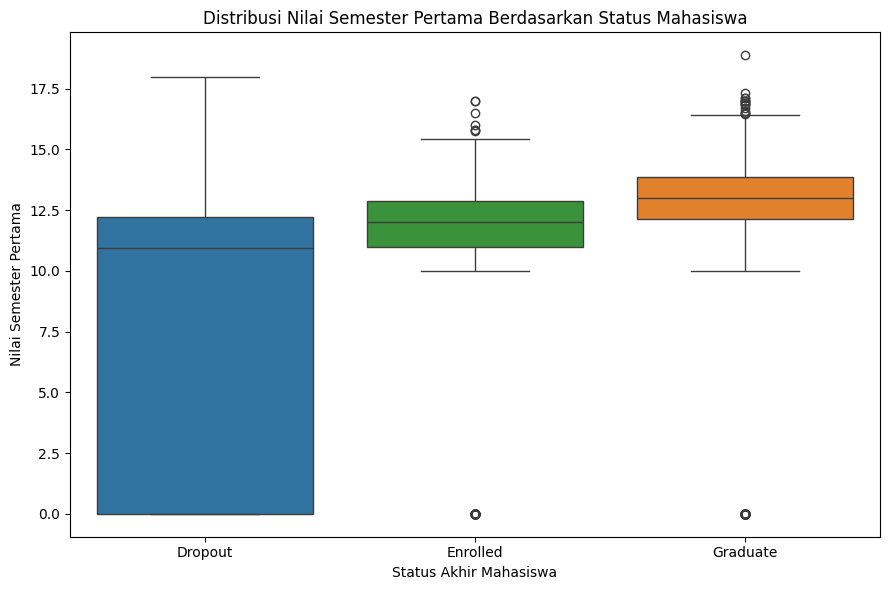

,count,mean,median,min,max
Target,,,,,
Dropout,1421,7.26,10.93,0.0,18.00
Enrolled,794,11.13,12.00,0.0,17.00
Graduate,2209,12.64,13.00,0.0,18.88


In [ ]:

plt.figure(figsize=(9, 6))

sns.boxplot(
    data=df,
    x="Target",
    y="Curricular units 1st sem (grade)",
    order=["Dropout", "Enrolled", "Graduate"],
    hue="Target",
    legend=False
)

plt.title("Distribusi Nilai Semester Pertama Berdasarkan Status Mahasiswa")
plt.xlabel("Status Akhir Mahasiswa")
plt.ylabel("Nilai Semester Pertama")
plt.tight_layout()
plt.show()

# Ringkasan nilai per status
ringkasan_nilai = (
    df.groupby("Target")["Curricular units 1st sem (grade)"]
    .agg(["count", "mean", "median", "min", "max"])
    .round(2)
)

display(ringkasan_nilai.loc[["Dropout", "Enrolled", "Graduate"]])


,count,mean,median,min,max
Target,,,,,
Dropout,1421,2.55,2.0,0,21
Enrolled,794,4.32,5.0,0,15
Graduate,2209,6.23,6.0,0,26


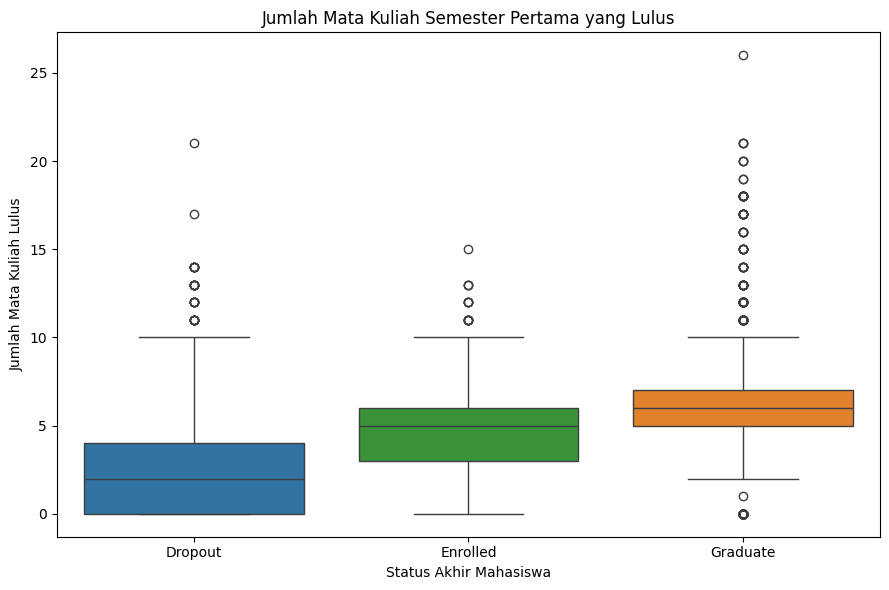

In [ ]:

# Membandingkan jumlah mata kuliah yang lulus
kolom = "Curricular units 1st sem (approved)"

ringkasan_lulus = (
    df.groupby("Target")[kolom]
    .agg(["count", "mean", "median", "min", "max"])
    .round(2)
)

display(ringkasan_lulus.loc[["Dropout", "Enrolled", "Graduate"]])

# Membuat boxplot
plt.figure(figsize=(9, 6))

sns.boxplot(
    data=df,
    x="Target",
    y=kolom,
    order=["Dropout", "Enrolled", "Graduate"],
    hue="Target",
    legend=False
)

plt.title("Jumlah Mata Kuliah Semester Pertama yang Lulus")
plt.xlabel("Status Akhir Mahasiswa")
plt.ylabel("Jumlah Mata Kuliah Lulus")
plt.tight_layout()
plt.show()


Korelasi Pearson: 0.837


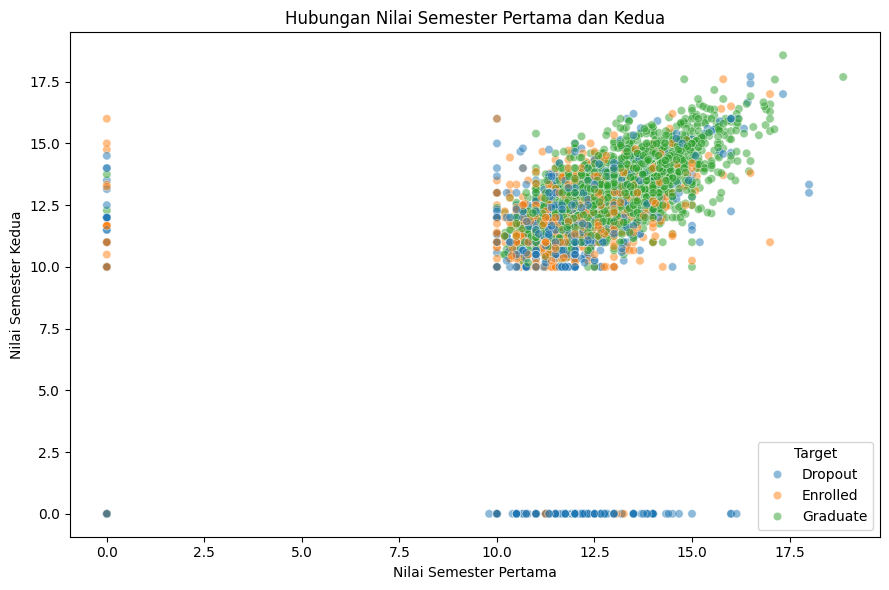

In [ ]:

kolom_1 = "Curricular units 1st sem (grade)"
kolom_2 = "Curricular units 2nd sem (grade)"

# Menghitung korelasi Pearson
korelasi = df[[kolom_1, kolom_2]].corr().iloc[0, 1]
print(f"Korelasi Pearson: {korelasi:.3f}")

# Scatter plot
plt.figure(figsize=(9, 6))

sns.scatterplot(
    data=df,
    x=kolom_1,
    y=kolom_2,
    hue="Target",
    hue_order=["Dropout", "Enrolled", "Graduate"],
    alpha=0.5
)

plt.title("Hubungan Nilai Semester Pertama dan Kedua")
plt.xlabel("Nilai Semester Pertama")
plt.ylabel("Nilai Semester Kedua")
plt.tight_layout()
plt.show()


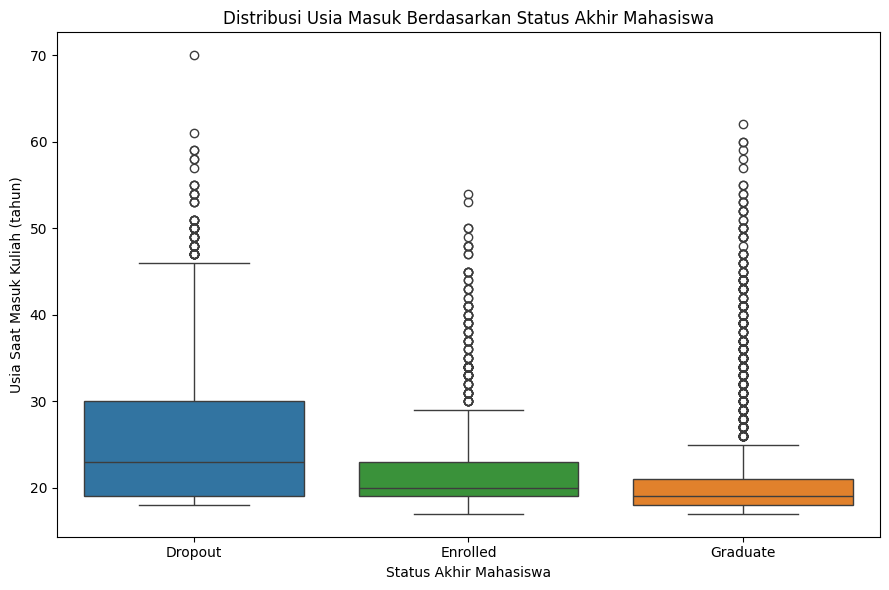

,count,mean,median,min,max
Target,,,,,
Dropout,1421,26.07,23.0,18,70
Enrolled,794,22.37,20.0,17,54
Graduate,2209,21.78,19.0,17,62


In [ ]:
plt.figure(figsize=(9, 6))

sns.boxplot(
    data=df,
    x="Target",
    y="Age at enrollment",
    order=["Dropout", "Enrolled", "Graduate"],
    hue="Target",
    legend=False
)

plt.title("Distribusi Usia Masuk Berdasarkan Status Akhir Mahasiswa")
plt.xlabel("Status Akhir Mahasiswa")
plt.ylabel("Usia Saat Masuk Kuliah (tahun)")
plt.tight_layout()
plt.show()

ringkasan_usia = df.groupby("Target")["Age at enrollment"].agg(
    ["count", "mean", "median", "min", "max"]
).round(2)

display(ringkasan_usia.loc[["Dropout", "Enrolled", "Graduate"]])

Target,Dropout,Enrolled,Graduate
Gender,,,
0,720,487,1661
1,701,307,548


Target,Dropout,Enrolled,Graduate
Gender,,,
0,25.10,16.98,57.91
1,45.05,19.73,35.22


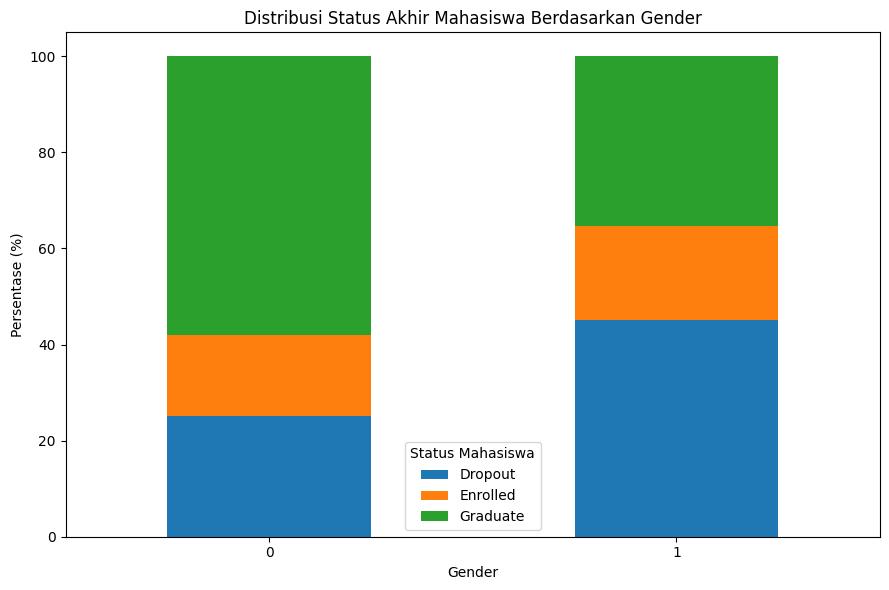

In [ ]:
# Menghitung jumlah mahasiswa berdasarkan jenis kelamin dan status
tabel_gender = pd.crosstab(
    df["Gender"],
    df["Target"]
)

display(tabel_gender)

# Menghitung persentase status di setiap kelompok gender
persentase_gender = pd.crosstab(
    df["Gender"],
    df["Target"],
    normalize="index"
) * 100

display(persentase_gender.round(2))

# Membuat grafik
persentase_gender.plot(
    kind="bar",
    stacked=True,
    figsize=(9, 6)
)

plt.title("Distribusi Status Akhir Mahasiswa Berdasarkan Gender")
plt.xlabel("Gender")
plt.ylabel("Persentase (%)")
plt.legend(title="Status Mahasiswa")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

Tabel Korelasi Antarvariabel:


,Curricular units 1st sem (grade),Curricular units 2nd sem (grade),Curricular units 1st sem (approved),Curricular units 2nd sem (approved),Age at enrollment
Curricular units 1st sem (grade),1.000,0.837,0.696,0.673,-0.157
Curricular units 2nd sem (grade),0.837,1.000,0.686,0.761,-0.173
Curricular units 1st sem (approved),0.696,0.686,1.000,0.904,-0.053
Curricular units 2nd sem (approved),0.673,0.761,0.904,1.000,-0.112
Age at enrollment,-0.157,-0.173,-0.053,-0.112,1.000


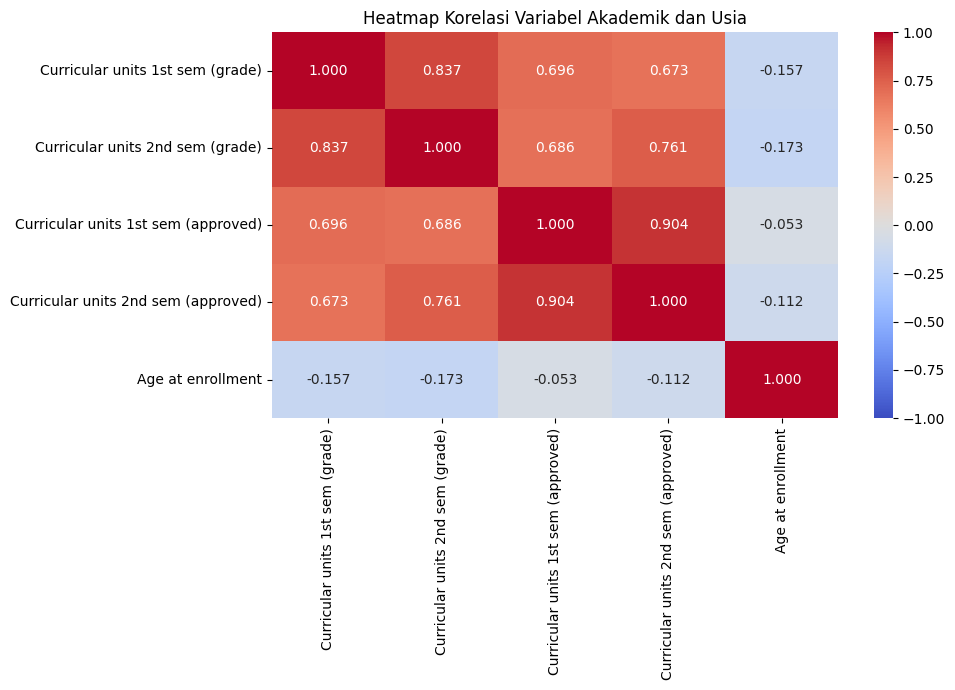

In [ ]:

# Memilih variabel yang akan dianalisis
kolom_akademik = [
    "Curricular units 1st sem (grade)",
    "Curricular units 2nd sem (grade)",
    "Curricular units 1st sem (approved)",
    "Curricular units 2nd sem (approved)",
    "Age at enrollment"
]

# Menghitung matriks korelasi
matriks_korelasi = df[kolom_akademik].corr()

# 1. Menampilkan tabel angka korelasi
print("Tabel Korelasi Antarvariabel:")
display(matriks_korelasi.round(3))

# 2. Menampilkan heatmap
plt.figure(figsize=(10, 7))

sns.heatmap(
    matriks_korelasi,
    annot=True,
    cmap="coolwarm",
    fmt=".3f",
    vmin=-1,
    vmax=1
)

plt.title("Heatmap Korelasi Variabel Akademik dan Usia")
plt.tight_layout()
plt.show()


In [13]:

# Menampilkan informasi variabel Gender dari dokumentasi dataset
print(dataset.variables[
    dataset.variables["name"].str.contains("Gender", case=False, na=False)
].to_string(index=False))



  name    role    type demographic         description units missing_values
Gender Feature Integer      Gender 1 – male 0 – female  None             no
